# 01 EDA
Partitions: **train** (80 trips) and **student_test** (10 trips). Every output is labelled with its partition. evaluator-test data is not available and not used.

In [1]:
import sys, os, glob, yaml
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, networkx as nx, matplotlib
import matplotlib.pyplot as plt
from pyproj import Transformer
from shapely import STRtree, LineString, points
from io_utils import load_trip, get_utm_crs
cfg = yaml.safe_load(open("../configs/config.yaml"))
DIRS = {"train": "../" + cfg["train_dir"], "student_test": "../" + cfg["test_dir"]}
os.makedirs("../results/csv", exist_ok=True); os.makedirs("../results/plots", exist_ok=True); os.makedirs("../results/maps", exist_ok=True)
trips = [(p, tid, os.path.join(d, tid)) for p, d in DIRS.items() for tid in sorted(os.listdir(d))]
len(trips)

90

## 1. Inventory (train / student_test)

In [2]:
rows = []
for p, tid, d in trips:
    r = {"partition": p, "trip_id": tid, "n_files": len(os.listdir(d))}
    for ext in ["track", "nodes", "arcs", "route"]:
        f = f"{d}/{tid}.{ext}"
        r[ext + "_kb"] = round(os.path.getsize(f) / 1024, 1) if os.path.exists(f) else np.nan
        r["n_" + ext] = sum(1 for _ in open(f)) if os.path.exists(f) else np.nan
    rows.append(r)
inv = pd.DataFrame(rows)
inv.to_csv("../results/csv/eda_inventory.csv", index=False)
print(inv.groupby("partition").agg(trips=("trip_id", "count"), files_per_trip=("n_files", "max")))
print("\nGPS points per trip, by partition:"); print(inv.groupby("partition")["n_track"].describe().round(1))
inv.head()

              trips  files_per_trip
partition                          
student_test     10               4
train            80               4

GPS points per trip, by partition:
              count    mean     std    min    25%     50%     75%      max
partition                                                                 
student_test   10.0  1916.0  1335.4  262.0  917.8  1420.0  2872.0   3958.0
train          80.0  2605.2  3312.3  361.0  945.8  1529.0  2792.8  19313.0


,partition,trip_id,n_files,track_kb,n_track,nodes_kb,n_nodes,arcs_kb,n_arcs,route_kb,n_route
0,train,00000001,4,40.0,1315,1647.8,88809,1902.8,165790,3.0,525
1,train,00000002,4,232.5,7243,155.0,7936,152.9,16139,1.4,262
2,train,00000003,4,25.6,821,178.5,9138,171.6,18028,0.4,79
3,train,00000004,4,34.2,1064,143.6,7350,146.2,15499,1.5,320
4,train,00000005,4,32.6,1045,17.5,898,12.1,1579,0.4,105


## 2-6. Per-trip stats (one pass over all trips, both partitions)

In [3]:
stats, dts, miss = [], [], []
cache = {}  # trip_id -> (track, nodes, arcs, route) only for plotting later
for p, tid, d in trips:
    track, nodes, arcs, route = load_trip(d)
    # 2. missing / invalid
    bad_range = ((track.lon.abs() > 180) | (track.lat.abs() > 90)).sum()
    bad_node = ((nodes.lon.abs() > 180) | (nodes.lat.abs() > 90)).sum()
    miss.append({"partition": p, "trip_id": tid, "nan_track": int(track.isna().sum().sum()), "nan_nodes": int(nodes.isna().sum().sum()),
                 "nan_arcs": int(arcs.isna().sum().sum()), "track_out_of_range": int(bad_range), "nodes_out_of_range": int(bad_node),
                 "arc_node_oob": int(((arcs.to_numpy() < 0) | (arcs.to_numpy() >= len(nodes))).sum()),
                 "route_arc_oob": int(sum(a < 0 or a >= len(arcs) for a in route)),
                 "dup_track_pts": int(track.duplicated().sum()), "t_not_increasing": int((track.t.diff().dropna() <= 0).sum())})
    # 3. dt
    dt = track.t.diff().dropna()
    dts.append(pd.DataFrame({"partition": p, "trip_id": tid, "dt": dt.values}))
    # 4. bbox + utm
    lon0, lat0 = track.lon.mean(), track.lat.mean()
    crs = get_utm_crs(lon0, lat0)
    # 5. network
    G = nx.DiGraph(); G.add_nodes_from(range(len(nodes))); G.add_edges_from(arcs.to_numpy().tolist())
    comps = list(nx.weakly_connected_components(G))
    deg = np.bincount(arcs.to_numpy().ravel(), minlength=len(nodes))
    # 6. route chaining
    ra = arcs.loc[route] if len(route) else arcs.iloc[:0]
    chain = (ra.to_node.to_numpy()[:-1] == ra.from_node.to_numpy()[1:]) if len(ra) > 1 else np.array([])
    stats.append({"partition": p, "trip_id": tid, "n_pts": len(track), "dur_s": track.t.iloc[-1] - track.t.iloc[0],
                  "dt_mean": dt.mean(), "dt_max": dt.max(), "pct_dt_1s": (dt == 1).mean() * 100, "n_gaps_gt5s": int((dt > 5).sum()),
                  "lon_min": track.lon.min(), "lon_max": track.lon.max(), "lat_min": track.lat.min(), "lat_max": track.lat.max(),
                  "mean_lon": lon0, "mean_lat": lat0, "utm_crs": crs,
                  "n_nodes": len(nodes), "n_arcs": len(arcs), "n_weak_comps": len(comps), "largest_comp": max(map(len, comps)),
                  "isolated_nodes": int((deg == 0).sum()), "route_len": len(route), "route_chain_pct": chain.mean() * 100 if len(chain) else np.nan})
    if tid in ("00000001", "00000007"): cache[tid] = (p, track, nodes, arcs, route)
S = pd.DataFrame(stats); M = pd.DataFrame(miss); DT = pd.concat(dts)
S.to_csv("../results/csv/eda_trip_stats.csv", index=False); M.to_csv("../results/csv/eda_missing_invalid.csv", index=False)
print("done", len(S))

done 90


In [4]:
# 2. missing / invalid, dtypes
print("Missing/invalid GPS & network values, summed per partition:")
print(M.drop(columns="trip_id").groupby("partition").sum())
t, n, a, r = load_trip(trips[0][2])
print("\ndtypes (partition train, trip", trips[0][1], "):"); print(pd.concat({"track": t.dtypes, "nodes": n.dtypes, "arcs": a.dtypes}).to_string()); print("route:", type(r[0]))

Missing/invalid GPS & network values, summed per partition:
              nan_track  nan_nodes  nan_arcs  track_out_of_range  \
partition                                                          
student_test          0          0         0                   0   
train                 0          0         0                   0   

              nodes_out_of_range  arc_node_oob  route_arc_oob  dup_track_pts  \
partition                                                                      
student_test                   0             0              0              0   
train                          0             0              0              0   

              t_not_increasing  
partition                       
student_test                 0  
train                        0  

dtypes (partition train, trip 00000001 ):
track  lon          float64
       lat          float64
       t            float64
nodes  lon          float64
       lat          float64
arcs   from_node      int64
   

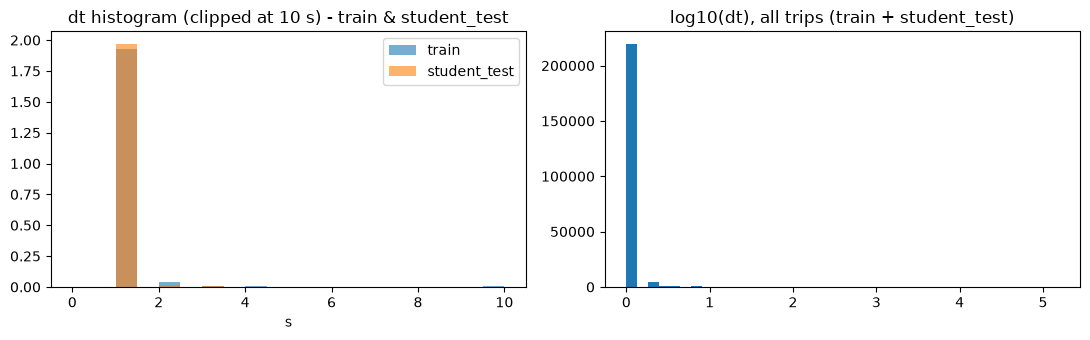

dt value counts, top 5 (train + student_test):
dt
1.0    219934
2.0      4461
3.0      1123
4.0       435
5.0       256
Name: count, dtype: int64
share dt==1s per partition:
partition
student_test    98.62
train           96.50
Name: dt, dtype: float64

trips with gaps > 5 s: 47 of 90


,partition,trip_id,n_pts,n_gaps_gt5s,dt_max
72,train,00000090,536,20,153064.0
61,train,00000078,2909,124,52810.0
55,train,00000069,2067,2,2658.0
16,train,00000021,15783,2,2161.0
8,train,00000011,2828,1,909.0
34,train,00000042,7739,45,670.0
64,train,00000081,3224,129,536.0
18,train,00000024,801,4,458.0
36,train,00000044,546,2,341.0
67,train,00000084,16031,4,312.0


In [5]:
# 3. time deltas
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for p in DIRS:
    x = DT[DT.partition == p].dt
    ax[0].hist(x.clip(upper=10), bins=np.arange(0, 10.5, 0.5), alpha=.6, label=p, density=True)
ax[0].set_title("dt histogram (clipped at 10 s) - train & student_test"); ax[0].set_xlabel("s"); ax[0].legend()
ax[1].hist(np.log10(DT.dt.clip(lower=0.1)), bins=40); ax[1].set_title("log10(dt), all trips (train + student_test)")
plt.tight_layout(); plt.savefig("../results/plots/eda_dt_hist.png", dpi=110); plt.show()
print("dt value counts, top 5 (train + student_test):"); print(DT.dt.value_counts().head())
print("share dt==1s per partition:"); print(DT.groupby("partition").dt.apply(lambda x: (x == 1).mean() * 100).round(2))
g = S[S.n_gaps_gt5s > 0][["partition", "trip_id", "n_pts", "n_gaps_gt5s", "dt_max"]]
g.to_csv("../results/csv/eda_gap_trips.csv", index=False)
print(f"\ntrips with gaps > 5 s: {len(g)} of {len(S)}"); g.sort_values("dt_max", ascending=False).head(15)

In [6]:
# 4. bbox + UTM zone
print("UTM zones across trips (train + student_test):"); print(S.groupby(["partition", "utm_crs"]).size().unstack(0).fillna(0).astype(int))
S[["partition", "trip_id", "lon_min", "lon_max", "lat_min", "lat_max", "utm_crs"]].round(4).head(10)

UTM zones across trips (train + student_test):
partition   student_test  train
utm_crs                        
EPSG:32614             0      1
EPSG:32615             1      1
EPSG:32616             0      2
EPSG:32617             0      3
EPSG:32622             0      1
EPSG:32629             0      3
EPSG:32630             0      9
EPSG:32631             1      6
EPSG:32632             0      8
EPSG:32633             1      6
EPSG:32634             0      5
EPSG:32635             0      3
EPSG:32636             1      4
EPSG:32637             0     10
EPSG:32638             1      3
EPSG:32639             2      2
EPSG:32640             1      1
EPSG:32641             1      3
EPSG:32643             1      1
EPSG:32648             0      1
EPSG:32651             0      1
EPSG:32653             0      3
EPSG:32721             0      1
EPSG:32722             0      1
EPSG:32735             0      1


,partition,trip_id,lon_min,lon_max,lat_min,lat_max,utm_crs
0,train,00000001,8.5705,8.6479,49.8441,50.2119,EPSG:32632
1,train,00000002,11.0000,11.0509,47.6583,47.6955,EPSG:32632
2,train,00000003,37.1542,37.2016,55.9771,56.0076,EPSG:32637
3,train,00000004,12.3423,12.4596,52.5903,52.7190,EPSG:32633
4,train,00000005,35.4856,35.5443,49.3576,49.6131,EPSG:32636
5,train,00000006,37.2760,37.3177,55.4292,55.4872,EPSG:32637
6,train,00000008,-86.5849,-86.5675,34.7333,34.7537,EPSG:32616
7,train,00000010,37.3579,37.3948,55.7863,55.8329,EPSG:32637
8,train,00000011,59.6471,60.0169,56.0418,56.0675,EPSG:32640
9,train,00000012,44.0445,44.3899,36.1759,36.2636,EPSG:32638


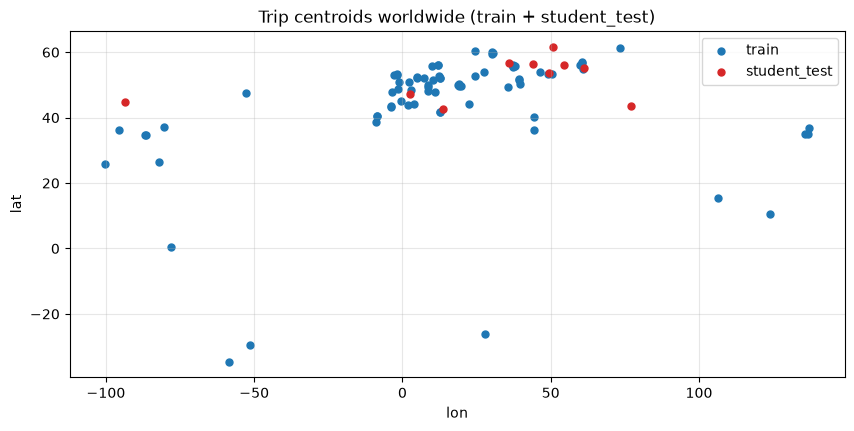

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for p, c in [("train", "tab:blue"), ("student_test", "tab:red")]:
    s = S[S.partition == p]; ax.scatter(s.mean_lon, s.mean_lat, c=c, label=p, s=25)
ax.set_title("Trip centroids worldwide (train + student_test)"); ax.set_xlabel("lon"); ax.set_ylabel("lat"); ax.legend(); ax.grid(alpha=.3)
plt.savefig("../results/plots/eda_trip_centroids.png", dpi=110); plt.show()

In [8]:
# 5. network
print("Network size & connectivity (train + student_test), per-trip distribution:")
print(S.groupby("partition")[["n_nodes", "n_arcs", "n_weak_comps", "largest_comp", "isolated_nodes"]].describe().T.round(1).to_string())
S["largest_comp_pct"] = S.largest_comp / S.n_nodes * 100
print("\nlargest weak component as % of nodes:"); print(S.groupby("partition").largest_comp_pct.describe().round(2))

Network size & connectivity (train + student_test), per-trip distribution:
partition             student_test     train
n_nodes        count          10.0      80.0
               mean         9068.9   24168.6
               std          7452.2   32272.3
               min          1770.0     299.0
               25%          4908.0    3487.8
               50%          6596.5    9608.0
               75%         11844.2   28846.8
               max         26635.0  155003.0
n_arcs         count          10.0      80.0
               mean        18504.1   48461.3
               std         15496.9   64738.8
               min          3577.0     649.0
               25%         10292.2    7061.8
               50%         13145.0   19526.5
               75%         24818.5   58003.2
               max         56027.0  307392.0
n_weak_comps   count          10.0      80.0
               mean           22.7      39.0
               std            29.2      60.7
               min       

In [9]:
# 6. route chain check
print("% consecutive route arcs with to_node == from_node (train + student_test):")
print(S.groupby("partition").route_chain_pct.describe().round(2))
print("route arcs missing (route_len==0):", (S.route_len == 0).groupby(S.partition).sum().to_dict())
S[["partition", "trip_id", "route_len", "route_chain_pct"]].sort_values("route_chain_pct").head(8)

% consecutive route arcs with to_node == from_node (train + student_test):
              count   mean   std    min    25%    50%    75%    max
partition                                                          
student_test   10.0  99.97  0.08  99.73  100.0  100.0  100.0  100.0
train          80.0  99.93  0.25  98.13  100.0  100.0  100.0  100.0
route arcs missing (route_len==0): {'student_test': 0, 'train': 0}


,partition,trip_id,route_len,route_chain_pct
60,train,00000075,108,98.130841
63,train,00000080,139,99.275362
26,train,00000033,169,99.404762
14,train,00000019,545,99.448529
1,train,00000002,262,99.616858
71,train,00000089,265,99.621212
33,train,00000041,340,99.705015
87,student_test,00000076,374,99.731903


## 7. GPS-to-reference-route distance (partition: **train** only)
Each trip projected into its own UTM zone.

GPS point -> nearest route arc distance, m (train, all 80 trips):
count    208417.00
mean         21.43
std          46.25
min           0.00
50%           5.61
90%          74.73
95%         140.27
99%         203.67
max         569.66
Name: dist_m, dtype: float64
share within 50 m (radius_m): 89.17 %


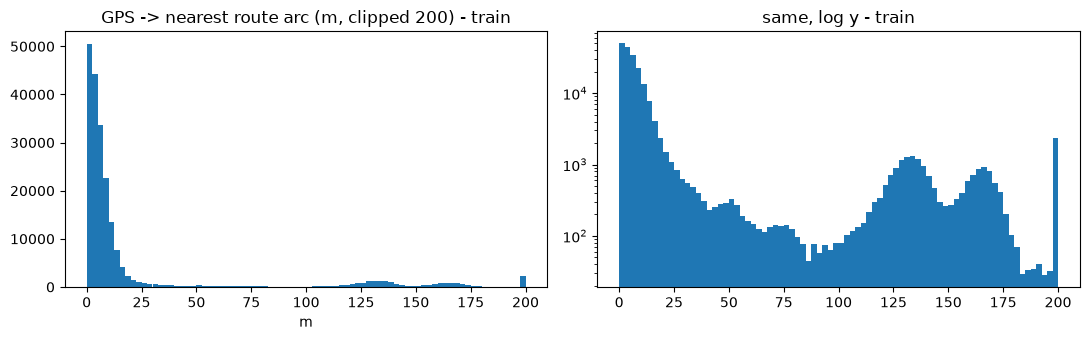

In [10]:
dist_rows = []
for p, tid, d in trips:
    if p != "train": continue
    track, nodes, arcs, route = load_trip(d)
    crs = S.loc[S.trip_id == tid, "utm_crs"].iloc[0]
    tf = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
    px, py = tf.transform(track.lon.values, track.lat.values)
    nx_, ny_ = tf.transform(nodes.lon.values, nodes.lat.values)
    ra = arcs.loc[route].to_numpy()
    segs = [LineString([(nx_[f], ny_[t_ := f]), (nx_[t], ny_[t])]) for f, t in ra] if False else [LineString([(nx_[f], ny_[f]), (nx_[t], ny_[t])]) for f, t in ra]
    tree = STRtree(segs)
    _, dist = tree.query_nearest(points(px, py), return_distance=True, all_matches=False)
    dist_rows.append(pd.DataFrame({"trip_id": tid, "dist_m": dist}))
D = pd.concat(dist_rows); D.to_csv("../results/csv/eda_gps_to_route_dist.csv", index=False)
print("GPS point -> nearest route arc distance, m (train, all 80 trips):"); print(D.dist_m.describe(percentiles=[.5, .9, .95, .99]).round(2))
print("share within 50 m (radius_m):", round((D.dist_m <= cfg["radius_m"]).mean() * 100, 2), "%")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(D.dist_m.clip(upper=200), bins=80); ax[0].set_title("GPS -> nearest route arc (m, clipped 200) - train"); ax[0].set_xlabel("m")
ax[1].hist(D.dist_m.clip(upper=200), bins=80); ax[1].set_yscale("log"); ax[1].set_title("same, log y - train")
plt.tight_layout(); plt.savefig("../results/plots/eda_gps_to_route_dist.png", dpi=110); plt.show()

## 8. GPS scatter and trajectory plots

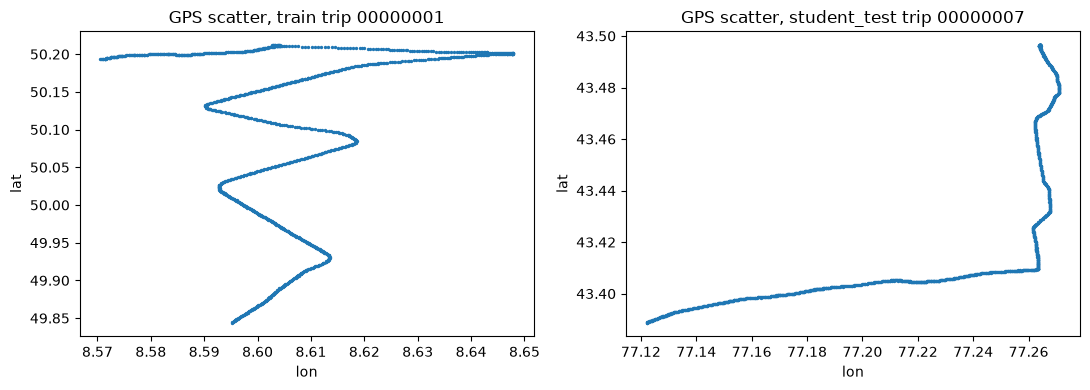

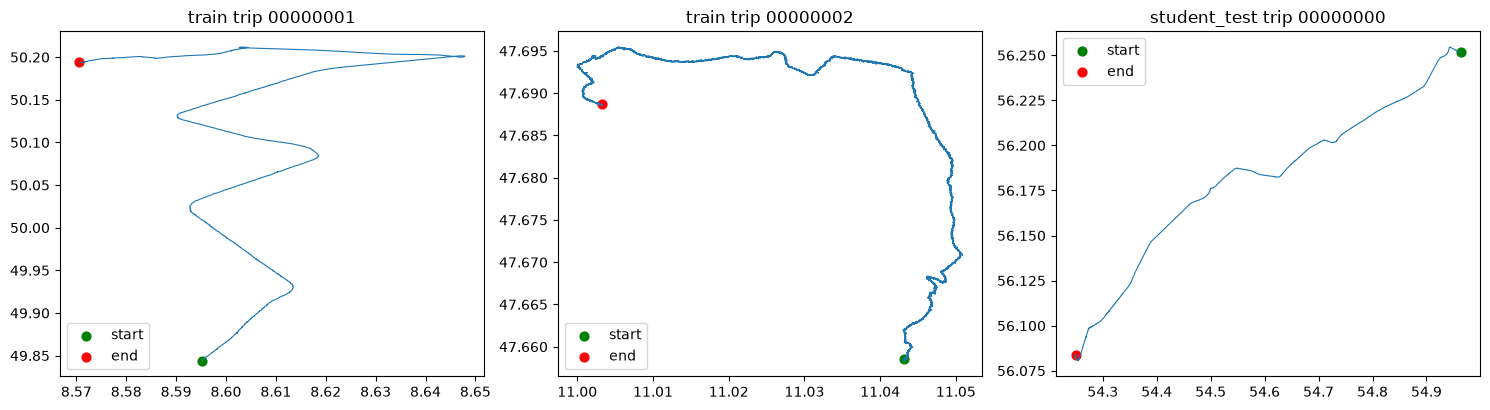

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, (tid, (p, track, nodes, arcs, route)) in enumerate(cache.items()):
    ax[k].scatter(track.lon, track.lat, s=2); ax[k].set_title(f"GPS scatter, {p} trip {tid}"); ax[k].set_xlabel("lon"); ax[k].set_ylabel("lat")
plt.tight_layout(); plt.savefig("../results/plots/eda_gps_scatter.png", dpi=110); plt.show()
sel = [(p, tid) for p, tid, _ in trips if p == "train"][:2] + [(p, tid) for p, tid, _ in trips if p == "student_test"][:1]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a_, (p, tid) in zip(ax, sel):
    track, nodes, arcs, route = load_trip(DIRS[p] + "/" + tid)
    a_.plot(track.lon, track.lat, "-", lw=.8, c="tab:blue"); a_.scatter(track.lon.iloc[[0]], track.lat.iloc[[0]], c="green", s=40, label="start")
    a_.scatter(track.lon.iloc[[-1]], track.lat.iloc[[-1]], c="red", s=40, label="end"); a_.set_title(f"{p} trip {tid}"); a_.legend()
plt.tight_layout(); plt.savefig("../results/plots/eda_trajectories.png", dpi=110); plt.show()

## 9. Folium map (partition: **train**, one trip)

In [12]:
import folium
tid = "00000001"; p, track, nodes, arcs, route = cache[tid]
nl = nodes[["lon", "lat"]].to_numpy()
ra = arcs.loc[route]
rpts = np.vstack([nl[ra.from_node], nl[ra.to_node]])
from scipy.spatial import cKDTree
pad = 0.003
lo, hi = rpts.min(0) - pad, rpts.max(0) + pad
d_near, _ = cKDTree(np.unique(rpts, axis=0)).query(nl[arcs.from_node.to_numpy()])
near = arcs[d_near < 0.0015]  # ~150 m in degrees; full network too big for the map
print(f"trip {tid} ({p}): drawing {len(near)} of {len(arcs)} network arcs near the route")
m = folium.Map(location=[track.lat.mean(), track.lon.mean()], zoom_start=14, tiles="cartodbpositron")
fg_net, fg_route, fg_gps = (folium.FeatureGroup(n) for n in ["Road network (near route)", "Reference route", "GPS points"])
for f, t in zip(near.from_node, near.to_node):
    folium.PolyLine([(nl[f, 1], nl[f, 0]), (nl[t, 1], nl[t, 0])], color="grey", weight=1, opacity=.6).add_to(fg_net)
for f, t in zip(ra.from_node, ra.to_node):
    folium.PolyLine([(nl[f, 1], nl[f, 0]), (nl[t, 1], nl[t, 0])], color="green", weight=4).add_to(fg_route)
for lon, lat in track[["lon", "lat"]].itertuples(index=False):
    folium.CircleMarker((lat, lon), radius=2, color="blue", fill=True, weight=1).add_to(fg_gps)
for g in (fg_net, fg_route, fg_gps): g.add_to(m)
m.fit_bounds([[lo[1], lo[0]], [hi[1], hi[0]]])
legend = '<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:8px;border:1px solid #888;font-size:13px"><b>trip %s (train)</b><br><span style="color:grey">&#9473;</span> road network (near route)<br><span style="color:green">&#9473;</span> reference route<br><span style="color:blue">&#9679;</span> GPS points</div>' % tid
m.get_root().html.add_child(folium.Element(legend))
folium.LayerControl().add_to(m)
m.save("../results/maps/eda_trip.html")

trip 00000001 (train): drawing 7073 of 165790 network arcs near the route


/home/kesho/Desktop/ML_hackathon/.venv/lib/python3.14/site-packages/folium/raster_layers.py:129: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 10. Summary

In [13]:
tr, st = S[S.partition == "train"], S[S.partition == "student_test"]
summ = {"trips train/student_test": f"{len(tr)}/{len(st)}", "GPS pts/trip median train": tr.n_pts.median(), "GPS pts/trip median student_test": st.n_pts.median(),
        "dt==1s % (all)": round((DT.dt == 1).mean() * 100, 2), "trips with >5s gap": f"{int((S.n_gaps_gt5s > 0).sum())}/{len(S)}",
        "distinct UTM zones": S.utm_crs.nunique(), "nodes/trip median": S.n_nodes.median(), "arcs/trip median": S.n_arcs.median(),
        "median weak comps/trip": S.n_weak_comps.median(), "isolated nodes total": int(S.isolated_nodes.sum()),
        "route chain % median": round(S.route_chain_pct.median(), 2), "GPS->route dist median m (train)": round(D.dist_m.median(), 2),
        "GPS->route dist p95 m (train)": round(D.dist_m.quantile(.95), 2), "% GPS within 50 m of route (train)": round((D.dist_m <= 50).mean() * 100, 2)}
pd.Series(summ).to_csv("../results/csv/eda_summary.csv", header=["value"]); pd.Series(summ)

trips train/student_test                80/10
GPS pts/trip median train              1529.0
GPS pts/trip median student_test       1420.0
dt==1s % (all)                          96.68
trips with >5s gap                      47/90
distinct UTM zones                         25
nodes/trip median                      9305.0
arcs/trip median                      18761.5
median weak comps/trip                   19.0
isolated nodes total                        0
route chain % median                    100.0
GPS->route dist median m (train)         5.61
GPS->route dist p95 m (train)          140.27
% GPS within 50 m of route (train)      89.17
dtype: object

## 10. Data-quality issues, assumptions, decisions
**Findings (numbers from the cells above)**
- 80 train + 10 student_test trips, 4 files each (.track/.nodes/.arcs/.route). No NaN, no out-of-range lon/lat, no out-of-range node/arc ids, no duplicate or non-increasing timestamps in any trip.
- Sampling is nominally 1 Hz (96.7% of steps exactly 1 s) but 47 of 90 trips contain gaps > 5 s; the worst are huge (up to 153064 s, trips 78 and 90), so gaps must be handled (large-gap trips split or feature-capped).
- The 90 trips lie in 25 UTM zones across both hemispheres (lon about -100 to 137, lat about -35 to 62), so a single projection is wrong; each trip is projected to its own zone via `get_utm_crs`.
- Every trip ships its own road network (median about 9.3k nodes / 18.8k arcs, up to 155k nodes). The network is **not** connected: median 19 weakly connected components per trip, no isolated nodes. The route must stay inside one component, so connectivity matters for later HMM transitions.
- Reference routes chain almost perfectly (median 100% of consecutive arcs have to_node == from_node; the worst trip is 98.1%). The few breaks are treated as route limitations, not errors.
- Train only: median GPS-to-route distance is 5.6 m, p95 is 140 m, and only 89.2% of points lie within 50 m of the reference route. So `radius_m=50` alone would miss about 11% of true arcs. The candidate set must also include the K nearest arcs, and candidate miss rate must be reported.

**Assumptions / decisions**
- The reference route is treated as reference labels, not verified truth.
- Distances are measured in the per-trip UTM CRS (metres), never in degrees.
- Network, arcs and route are per trip; arc_id is only unique within a trip, so features key on (trip_id, arc_id).
- Learned preprocessing is fitted on the train partition only; student_test is used for development comparison only; evaluator data is not touched.
- The Folium map draws only network arcs within about 150 m of the route to keep the file small.